## ***Import Libraries***

In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import random_split, DataLoader, Dataset
from torchvision import datasets, models, transforms
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from PIL import Image
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

## ***Visualization***

In [3]:
dataset_path = '/kaggle/input/image-classification-64-classes-animal/image'

In [4]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])
dataset = datasets.ImageFolder(root=dataset_path, transform=transform)
class_names = dataset.classes

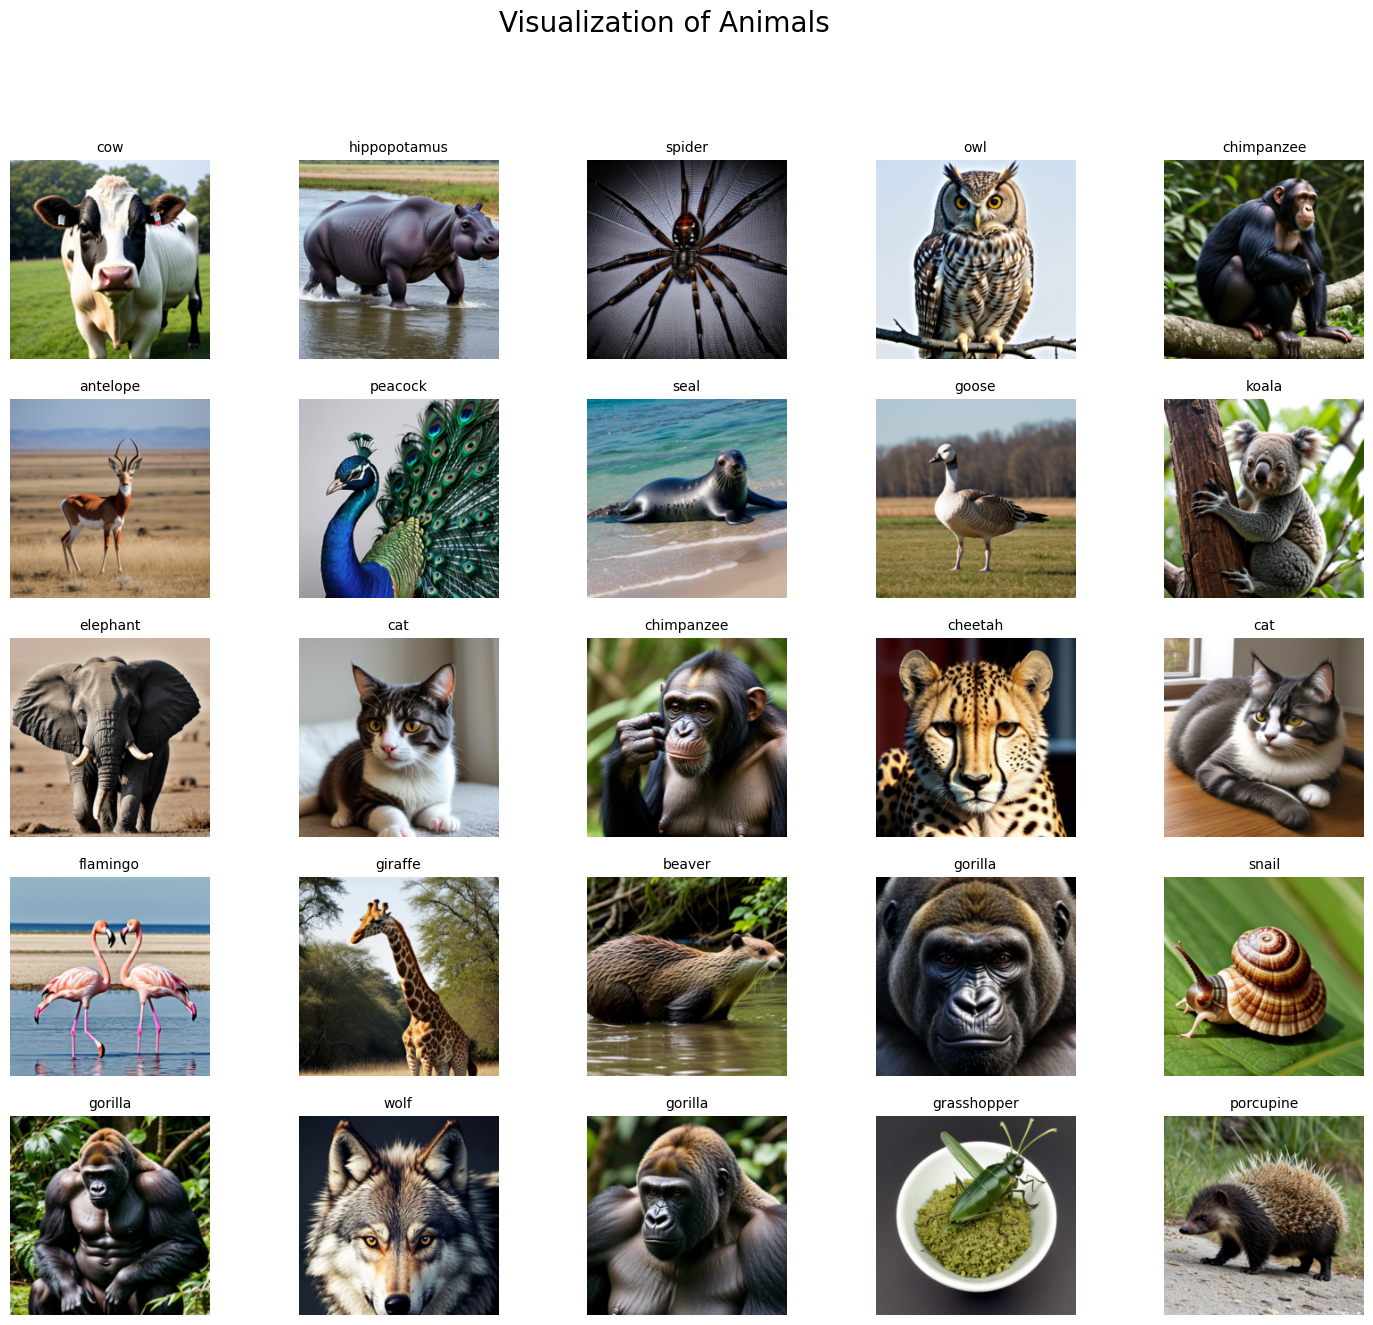

In [5]:
fig = plt.figure(figsize=(18, 15))
rows, cols = 5, 5
for i in range(1, rows * cols + 1):
    random_idx = torch.randint(0, len(dataset), size=[1]).item()
    img, label = dataset[random_idx]
    fig.add_subplot(rows, cols, i)
    plt.imshow(img.permute(1, 2, 0))
    plt.suptitle("Visualization of Animals", fontsize=20)
    plt.title(class_names[label], fontsize=10)
    plt.axis(False);

## ***Data Preparing and Preprocessing***

In [6]:

# we will write transform variable when use transforms function and after that we will apply over dataset
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.RandomHorizontalFlip(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

dataset = datasets.ImageFolder(root=dataset_path, transform=transform)

#Train-val and dataset split
train_size = int(0.70 * len(dataset)) # %70 Train
val_test_size = len(dataset) - train_size # %30 Val-Test
train_dataset, val_test_dataset = random_split(dataset, [train_size, val_test_size])

val_size = int(0.5 * len(val_test_dataset)) # Val
test_size = len(val_test_dataset) - val_size # Test
val_dataset, test_dataset = random_split(val_test_dataset, [val_size, test_size])

# Load dataset with Dataloader with batch size
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Check dataset dimensions
print(f"Number of Classes: {len(class_names)}")
print(f"Total data: {len(dataset)}")
print(f"Train data dimension: {len(train_dataset)}")
print(f"Val data dimension: {len(val_dataset)}")
print(f"Test data dimension: {len(test_dataset)}")

Number of Classes: 64
Total data: 14377
Train data dimension: 10063
Val data dimension: 2157
Test data dimension: 2157


In [7]:
try:
    # If multiple GPUs are available, use them
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    num_gpus = torch.cuda.device_count()
    print(f"Using {num_gpus} GPUs for training." if num_gpus > 1 else f"Using {torch.cuda.get_device_name()} for training." if torch.cuda.is_available() else "Using CPU for training.")
except:
    print("No GPU found. Using CPU.")
    device = torch.device("cpu")

Using 2 GPUs for training.


## ***Build the Ensemble Model(Resnet-Densenet)***

In [8]:
num_classes = len(class_names)

# ResNet Model
resnet_model = models.resnet152(pretrained=True)
resnet_model.classifier = nn.Linear(in_features=resnet_model.fc.in_features, out_features=num_classes)

if num_gpus > 1:
    resnet_model = nn.DataParallel(resnet_model).to(device)

Downloading: "https://download.pytorch.org/models/resnet152-394f9c45.pth" to /root/.cache/torch/hub/checkpoints/resnet152-394f9c45.pth
100%|██████████| 230M/230M [00:01<00:00, 187MB/s]  


## ***Train-Validation Functions***

In [10]:
# Training function
def train(model, train_loader, criterion, optimizer):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for batch_inputs, batch_labels in train_loader:
        batch_inputs, batch_labels = batch_inputs.to(device), batch_labels.to(device)
        optimizer.zero_grad()
        outputs = model(batch_inputs)
        loss = criterion(outputs, batch_labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += batch_labels.size(0)
        correct += (predicted == batch_labels).sum().item()
    average_loss = total_loss / len(train_loader)
    accuracy = correct / total * 100
    return average_loss, accuracy

# Validation function
def validate(model, val_loader, criterion):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_inputs, batch_labels in val_loader:
            batch_inputs, batch_labels = batch_inputs.to(device), batch_labels.to(device)
            outputs = model(batch_inputs)
            loss = criterion(outputs, batch_labels)
            total_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += batch_labels.size(0)
            correct += (predicted == batch_labels).sum().item()
    average_loss = total_loss / len(val_loader)
    accuracy = correct / total * 100
    return accuracy, average_loss

## ***Training***

In [11]:
# Define criterion and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(resnet_model.parameters(), lr=1e-4, weight_decay=1e-3)

# Training loop
num_epochs = 20
for epoch in range(num_epochs):
    train_loss, train_accuracy = train(resnet_model, train_loader, criterion, optimizer)
    val_accuracy, val_loss = validate(resnet_model, val_loader, criterion)
    print(f'Epoch [{epoch + 1}/{num_epochs}], Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.2f}%')

print('Training was completed')

Epoch [1/20], Train Loss: 0.7639, Train Accuracy: 88.76%, Validation Loss: 0.0160, Validation Accuracy: 99.77%
Epoch [3/20], Train Loss: 0.0160, Train Accuracy: 99.68%, Validation Loss: 0.0129, Validation Accuracy: 99.58%
Epoch [4/20], Train Loss: 0.0142, Train Accuracy: 99.73%, Validation Loss: 0.0146, Validation Accuracy: 99.49%
Epoch [5/20], Train Loss: 0.0191, Train Accuracy: 99.59%, Validation Loss: 0.0063, Validation Accuracy: 99.86%
Epoch [6/20], Train Loss: 0.0190, Train Accuracy: 99.60%, Validation Loss: 0.0259, Validation Accuracy: 99.44%
Epoch [7/20], Train Loss: 0.0247, Train Accuracy: 99.45%, Validation Loss: 0.0408, Validation Accuracy: 99.03%
Epoch [8/20], Train Loss: 0.0399, Train Accuracy: 99.13%, Validation Loss: 0.0626, Validation Accuracy: 98.84%
Epoch [9/20], Train Loss: 0.0304, Train Accuracy: 99.18%, Validation Loss: 0.0210, Validation Accuracy: 99.30%
Epoch [10/20], Train Loss: 0.0084, Train Accuracy: 99.79%, Validation Loss: 0.0129, Validation Accuracy: 99.81%


## ***Model Evaluating and Visualization of the Results***

In [12]:
# Test Func
def test(model, test_loader):
    model.eval()  # Evaluation mode
    all_preds = []
    all_labels = []
    
    with torch.no_grad():  # Disable gradient calculation
        for batch_inputs, batch_labels in test_loader:
            batch_inputs, batch_labels = batch_inputs.to(device), batch_labels.to(device)
            outputs = model(batch_inputs)
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(batch_labels.cpu().numpy())
    
    return all_preds, all_labels

# Testing Model
all_preds, all_labels = test(resnet_model, test_loader)

# Calculate test accuracy
accuracy = accuracy_score(all_labels, all_preds)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

# Precision, Recall, F1-Score 
precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted')
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")
print(f"F1-Score: {f1 * 100:.2f}%")

Test Accuracy: 99.58%
Precision: 99.60%
Recall: 99.58%
F1-Score: 99.58%


## ***Prediction***

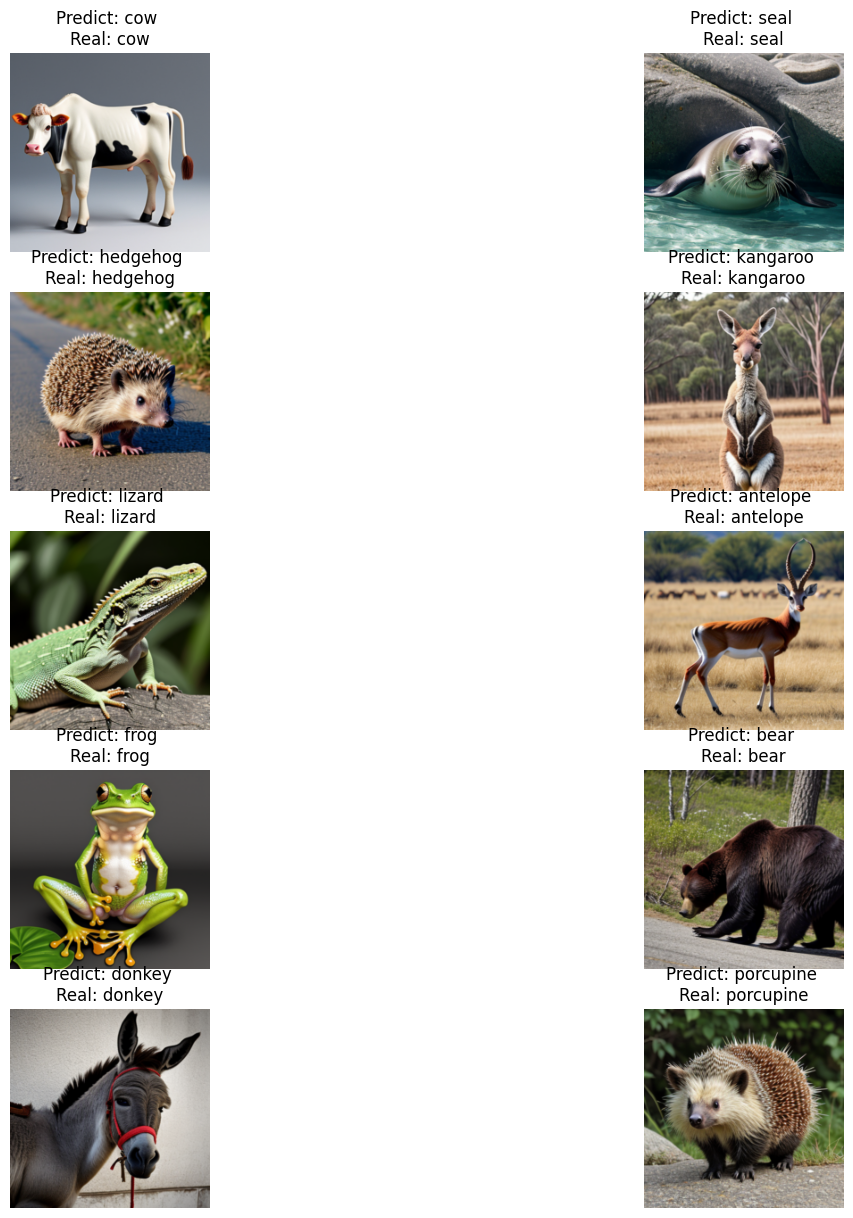

In [13]:
def predict_and_visualize_from_test(test_loader, model, class_names, num_images=5):
    model.eval()
    images_so_far = 0
    fig = plt.figure(figsize=(15, 15))

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            # Visualize images within each batch
            for i in range(inputs.size()[0]):
                if images_so_far == num_images:
                    return
                images_so_far += 1
                
                img = inputs[i].cpu().permute(1, 2, 0)  # Move image to CPU and edit channels
                img = img * torch.tensor([0.229, 0.224, 0.225]) + torch.tensor([0.485, 0.456, 0.406])  # Reverse normalization
                
                fig.add_subplot(num_images // 2, 2, images_so_far)
                plt.imshow(img)
                plt.title(f"Predict: {class_names[preds[i]]} \nReal: {class_names[labels[i]]}")
                plt.axis('off')

    plt.show()

predict_and_visualize_from_test(test_loader, resnet_model, class_names, num_images=10)

In [14]:
torch.save(resnet_model, "resnet_model.pth")